# Integration of Multiple Technologies

There are different technologies to obtain multi-channel images: CODEX, Imaging Mass Cytometry (IMC), MACSima imaging cyclic staining (MICS), MIBI, etc.
This notebook explores how you can use `spatialproteomics` to jointly analyse multiple modalities.

## Data Origin
The IMC data was downloaded from [here](https://figshare.com/articles/dataset/Raw_images_for_DLBCL_samples/20010146?file=35633237). It contains IMC images of DLBCL TMAs.

MICS data was downloaded from [here](https://zenodo.org/records/10057717). It contains a tonsil sample.

The CODEX data can be downloaded from [here](https://oc.embl.de/index.php/s/XzEa9po1tjiDzzJ). For this example, we consider three lymph node biopsies.

## Data Preparation

For all three data modalities, we follow the same general workflow of segmentation, protein quantification, and cell type prediction. Note that we do not need to use exactly the same tools, so if a certain segmentation method works better on one dataset than on the other, we can just apply different ones. 

Our downstream analysis is then carried out on the cell type level. This means that our data does not even need to have the same markers or cell types. The important part is that our cell type annotations should be sensible. We can then compare cell type abundances, interactions etc. across modalities and datasets.

In [1]:
import xarray as xr
import spatialproteomics as sp
from glob import glob
import tifffile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

celltype_colors = {
    "B cell": "#5799d1",
    "T cell": "#ebc850",
    "Myeloid cell": "#de6866",
    "Dendritic cell": "#4cbcbd",
    "Macrophage": "#bb7cb4",
    "Macrophage (M2)": "#bb7cb4",
    "Stromal cell": "#62b346",
    "Endothelial cell": "#bf997d",
}

### Imaging Mass Cytometry (IMC)

For the IMC data, we have a diffuse large B cell lymphoma (DLBCL) sample. The data is comprised of individual tiff files (one per marker), as well as a tiff file containing a segmentation that was performed with `ilastik`. The first step is to read this data into `spatialproteomics`.

In [2]:
def read_imc_data(path):
    # === DATA READING ===
    images = []
    markers = []
    for file in glob(path + "*.tiff"):
        if "ilastik" in file:
            continue
        marker_name = file.split("/")[-1].replace(".tiff", "")
        images.append(tifffile.imread(file))
        markers.append(marker_name)
    image = np.stack(images)

    segmentation = tifffile.imread(path + "DLBCL TMA #5_1_3964_1_a0_ilastik_s2_Probabilities_mask.tiff")

    # === CONVERTING TO SPATIALPROTEOMICS ===
    ds_imc = sp.load_image_data(image, channel_coords=markers, segmentation=segmentation)
    return ds_imc


ds_imc = read_imc_data("../../data/raw-ablated-files/3964_DLBCL TMA #5_1_3964_1/")

Now that we have a dataset, we can look at the markers.

In [3]:
ds_imc["channels"].values

array(['Histone3.Yb176Di', 'DNA.Ir193Di', 'CD45RA.Gd155Di',
       'Vimentin.Nd143Di', 'Ki67.Er168Di', 'Membrane.In115Di',
       'Tim3.Sm154Di', 'ICOS.Nd148Di', 'PD1.NAT105..Lu175Di',
       'EphrinB2.Er166Di', 'CD20.Dy161Di', 'BCL2.Nd146Di', 'BCL6.Sm147Di',
       'FOXP3.Dy163Di', 'Vista.Dy160Di', 'Lag3.Eu153Di', 'C.Myc.Dy164Di',
       'CD3.Er170Di', 'p.Stat3.Gd158Di', 'CD134.Eu151Di', 'CCR4.Sm149Di',
       'CD206.Tm169Di', 'DNA2.Ir191Di', 'CXCR3.Nd142Di', 'CD68.Tb159Di',
       'Granzym.B.Er167Di', 'CD45RO.Yb173Di', 'CD8.Dy162Di',
       'PDL1.Nd150Di', 'CD4.Gd156Di', 'CD30.Ho165Di', 'Tbet.Nd145Di',
       'CD31.Nd144Di', 'HLADR.Yb174Di', 'PDL2.Yb172Di'], dtype='<U19')

We can now use these markers to predict cell types. This step involves thresholding the different channels. After thresholding, you should always ensure that your cell type labels look sensible.

In [4]:
marker_to_celltype = {
    "CD20.Dy161Di": "B cell",
    "CD3.Er170Di": "T cell",
    "CD31.Nd144Di": "Endothelial cell",
    "CD68.Tb159Di": "Macrophage",
    "Vimentin.Nd143Di": "Stromal cell",
}

marker_to_color = {k: celltype_colors.get(v) for k, v in marker_to_celltype.items()}

threshold_dict = {
    "CD20.Dy161Di": 0.5,
    "CD3.Er170Di": 0.5,
    "CD31.Nd144Di": 0.8,
    "CD68.Tb159Di": 0.8,
    "Vimentin.Nd143Di": 0.8,
}

ds_imc = (
    ds_imc.pp.threshold(quantile=threshold_dict.values(), channels=threshold_dict.keys())
    .pp.add_quantification(func="intensity_mean")
    .pp.transform_expression_matrix(method="arcsinh")
    .la.predict_cell_types_argmax(marker_to_celltype)
    .la.set_label_colors(celltype_colors.keys(), celltype_colors.values())
)

Label Myeloid cell not found in the data object. Skipping.
Label Dendritic cell not found in the data object. Skipping.
Label Macrophage (M2) not found in the data object. Skipping.


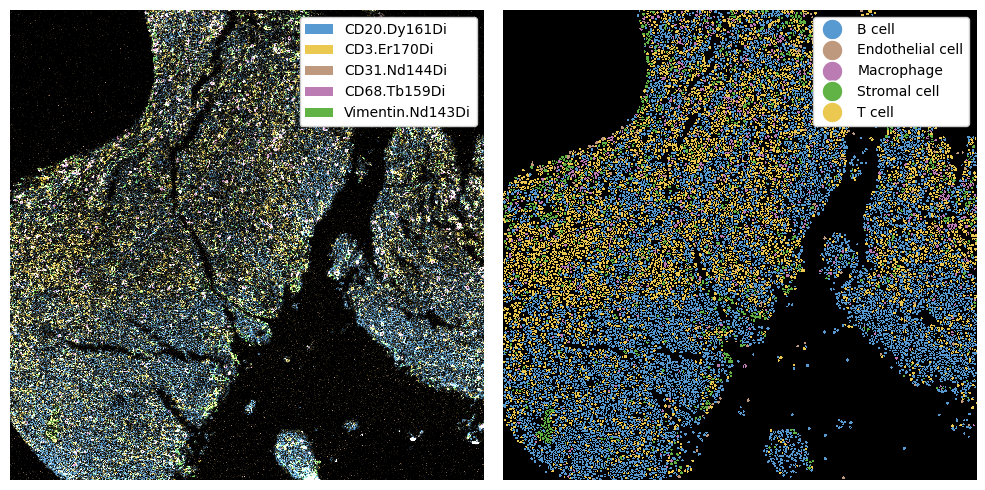

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
_ = ds_imc.pp[marker_to_color.keys()].pl.colorize(marker_to_color.values()).pl.show(ax=ax[0])
_ = ds_imc.pl.show(render_image=False, render_labels=True, ax=ax[1])
for axis in ax:
    axis.axis("off")
plt.tight_layout()
plt.show()

### MACSima imaging cyclic staining (MICS)
For MICS, we have a tonsil sample with high resolution. To illustrate how you can use `spatialproteomics` across different methods, we use `cellpose` to segment the cells based on DAPI and CD45.

In [6]:
def read_mics_data(path):
    # === DATA READING ===
    images = []
    markers = []

    image_shape = (7253, 9182)
    for file in glob(path + "*.tif"):
        marker_name = file.split("/")[-1].split("ROI-21_A-")[-1].replace(".tif", "")
        img = tifffile.imread(file)
        if img.shape != image_shape:
            print(f"The image for marker {marker_name} had shape {img.shape}, expected {image_shape}. Continuing...")
            continue
        if marker_name in markers:
            print(f"Already found marker {marker_name}, continuing...")
            continue
        images.append(img)
        markers.append(marker_name)

    image = np.stack(images)
    del images

    # === CONVERTING TO SPATIALPROTEOMICS ===
    ds_mics = sp.load_image_data(image, channel_coords=markers)
    return ds_mics


ds_mics = read_mics_data("../../data/Tonsil 2 - processed images/")

The image for marker AFP had shape (7060, 9184), expected (7253, 9182). Continuing...
Already found marker PE, continuing...
Already found marker FITC, continuing...


In [7]:
# downsampling the image for faster runtime
# also removing the top part of the image to get rid of a CD11c artefact
ds_mics = ds_mics.pp[:, :6000].pp.downsample(8).tl.cellpose(channel=["DAPI", "CD45"])

** TORCH CUDA version installed and working. **
>>>> using GPU (CUDA)
>>>> loading model /home/meyerben/.cellpose/models/cpsam


Next, we can once again predict cell types. While our markers are different now, our celltypes are still the same. This means that we can still compare things such as cell type abundances and cell-cell interactions later, assuming our cell type predictions are sensible for all technologies.

In [8]:
marker_to_celltype = {
    "CD20": "B cell",
    "CD3": "T cell",
    "CD31": "Endothelial cell",
    "CD11b": "Myeloid cell",
    "CD163": "Macrophage (M2)",
    "CD11c": "Dendritic cell",
}

marker_to_color = {k: celltype_colors.get(v) for k, v in marker_to_celltype.items()}

threshold_dict = {
    "CD20": 0.5,
    "CD3": 0.6,
    "CD31": 0.98,
    "CD163": 0.55,
    "CD11c": 0.95,
    "CD11b": 0.6,
}

ds_mics = (
    ds_mics.pp.threshold(quantile=threshold_dict.values(), channels=threshold_dict.keys())
    .pp.add_quantification(func="intensity_mean")
    .pp.transform_expression_matrix(method="arcsinh")
    .la.predict_cell_types_argmax(marker_to_celltype)
    .la.set_label_colors(celltype_colors.keys(), celltype_colors.values())
)

Label Macrophage not found in the data object. Skipping.
Label Stromal cell not found in the data object. Skipping.


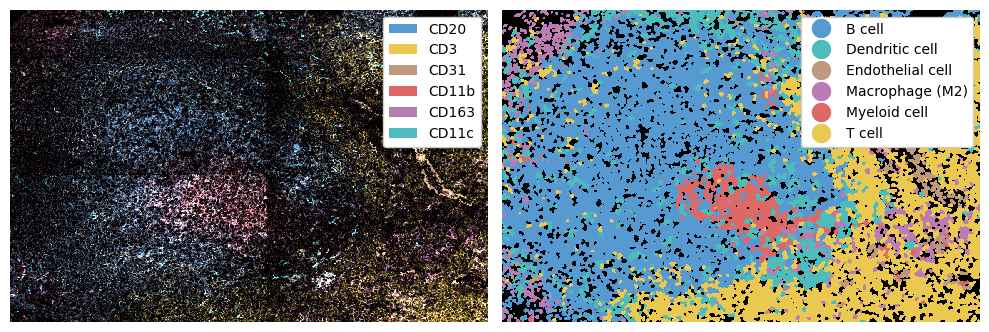

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
_ = ds_mics.pp[marker_to_color.keys()].pl.colorize(marker_to_color.values()).pl.show(ax=ax[0])
_ = ds_mics.pl.show(render_image=False, render_labels=True, ax=ax[1])
for axis in ax:
    axis.axis("off")
plt.tight_layout()
plt.show()

### CODEX
Here we consider three lymph node cores. These were segmented with `cellpose`, meaning that our three technologies were all segmented with different methods. In addition, we do not have all markers in all datasets, but since we perform cell type prediction, we can perform comparisons between cell types later on.

In [10]:
marker_to_celltype = {
    "PAX5": "B cell",
    "CD3": "T cell",
    "CD11b": "Myeloid cell",
    "CD68": "Macrophage",
    "CD11c": "Dendritic cell",
    "CD90": "Stromal cell",
    "Podoplanin": "Stromal cell",
    "CD31": "Endothelial cell",
    "CD34": "Endothelial cell",
}

marker_to_color = {k: celltype_colors.get(v) for k, v in marker_to_celltype.items()}

codex_ids = ["LN_11_1", "LN_13_1", "LN_24_1"]
codex_ds_dict = {
    x: xr.open_zarr(f"../../data/{x}.zarr")
    .la.set_label_level("labels_0", ignore_neighborhoods=True)
    .la.set_label_colors(celltype_colors.keys(), celltype_colors.values())
    for x in codex_ids
}

Label Macrophage (M2) not found in the data object. Skipping.
Label Macrophage (M2) not found in the data object. Skipping.
Label Macrophage (M2) not found in the data object. Skipping.


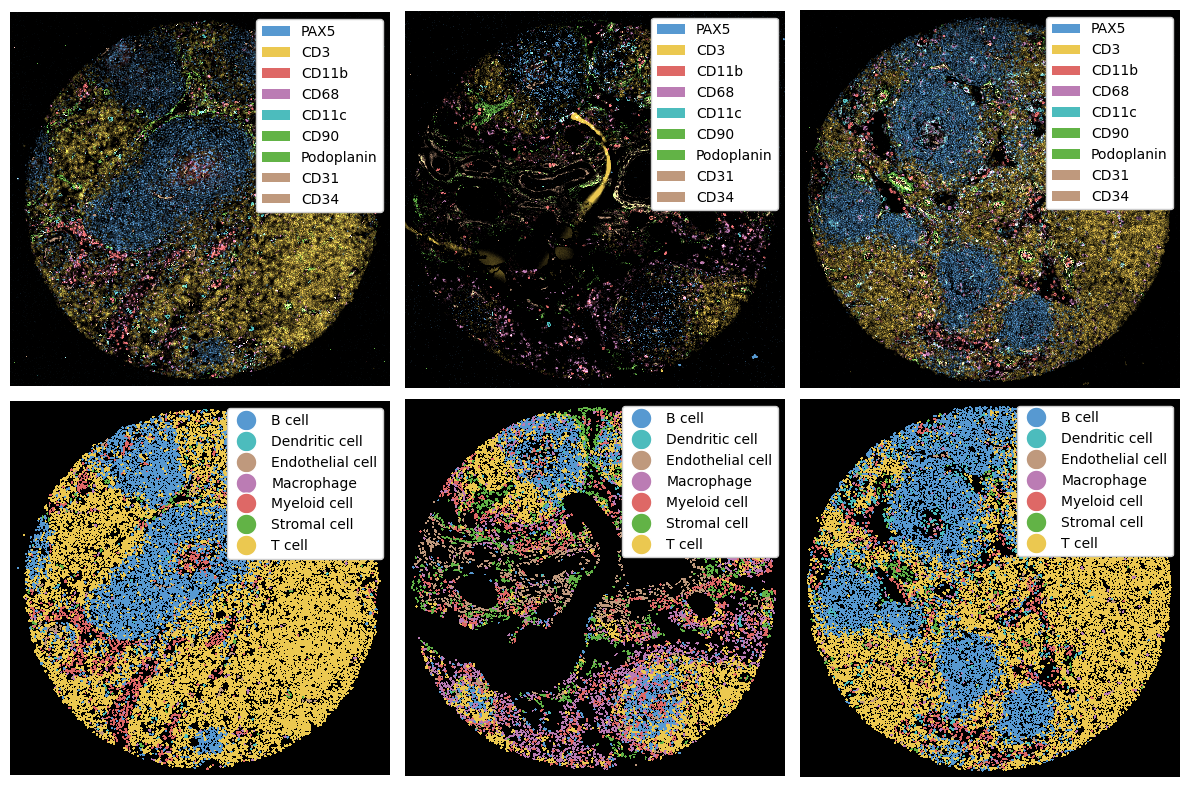

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()
i = 0

for sample_id, ds in codex_ds_dict.items():
    _ = ds.pl.autocrop().pp[marker_to_color.keys()].pl.colorize(marker_to_color.values()).pl.show(ax=ax[i])
    _ = ds.pl.autocrop().pl.show(render_image=False, render_labels=True, ax=ax[i + 3])
    i += 1

for axis in ax:
    axis.axis("off")

plt.tight_layout()
plt.show()

## Comparing cell type abundances

We can now compare the cell type abundances across the different modalities and datasets, as demonstrated below.

In [12]:
# Get counts for each modality
counts_imc = ds_imc.pp.get_layer_as_df()["_labels"].value_counts()
counts_mics = ds_mics.pp.get_layer_as_df()["_labels"].value_counts()
counts_codex = (
    pd.concat([ds.pp.get_layer_as_df()["_labels"].value_counts() for ds in codex_ds_dict.values()], axis=1)
    .fillna(0)
    .sum(axis=1)
    .astype(int)
)

# Put into one dataframe
df = pd.DataFrame({"IMC (DLBCL)": counts_imc, "MICS (Tonsil)": counts_mics, "CODEX (LN)": counts_codex}).fillna(0)

# Convert to relative abundances (fractions per modality)
df_rel = df.div(df.sum(axis=0), axis=1)

# Reshape into long format for seaborn
df_rel = (
    df_rel.reset_index()
    .melt(
        id_vars="_labels",
        value_vars=["IMC (DLBCL)", "MICS (Tonsil)", "CODEX (LN)"],
        var_name="Modality",
        value_name="Relative Abundance",
    )
    .rename(columns={"_labels": "CellType"})
)

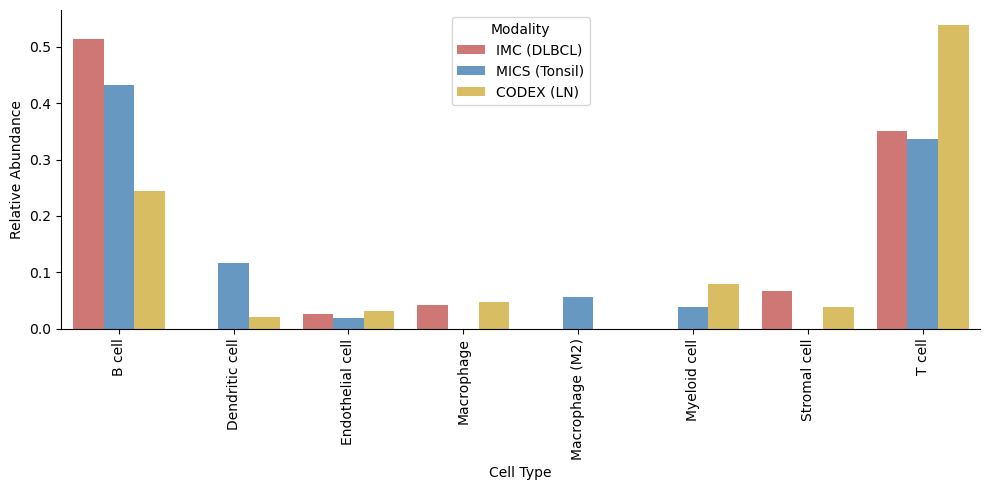

In [13]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_rel,
    x="CellType",
    y="Relative Abundance",
    hue="Modality",
    palette={"IMC (DLBCL)": "#de6966", "MICS (Tonsil)": "#5799d1", "CODEX (LN)": "#ebc84f"},
)

plt.xticks(rotation=90, ha="center")
plt.xlabel("Cell Type")
sns.despine()
plt.tight_layout()
plt.show()

## Reading Other File Formats
To load data, `spatialproteomics` expects an image (in the form of a numpy array), as well as a list of channels. Some technologies (such as COMET) output files in OME-tiff format.
Here, we show how to read in such data. This data can be downloaded from [here](https://github.com/filippocastelli/pyometiff/blob/main/tests/cell.ome.tiff).

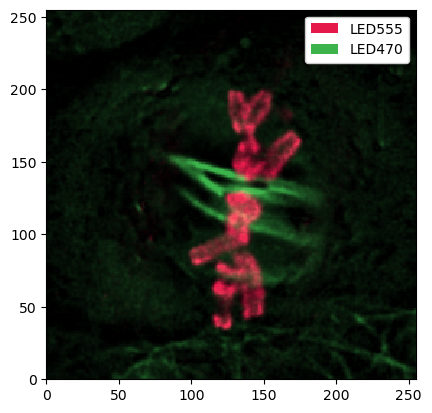

In [14]:
import tifffile
import xml.etree.ElementTree as ET

file = "../../data/cell.ome.tiff"

with tifffile.TiffFile(file) as tif:
    img = tif.asarray()[0, 0, :, :, :]  # numpy array
    ome_xml = tif.ome_metadata  # OME-XML as string

# Getting the channels directly from the OME-TIFF file
root = ET.fromstring(ome_xml)
ns = {"ome": "http://www.openmicroscopy.org/Schemas/OME/2016-06"}
channels = [ch.attrib["Name"] for ch in root.findall(".//ome:Channel", ns)]

# reading into spatialproteomics
ds = sp.load_image_data(img, channels)
_ = ds.pl.show()